# EfficientNet-B0 baseline (training scheme, Stage 1): train on your own computer

Trains the three Stage 1 EfficientNet-B0 models with `stage1/stage1a/config.yaml`, following
`training_scheme.md`. Section 3 checks every fixed §1–§5 value of the config (and of each finished run's saved
`config.yaml`) against the scheme and stops if one differs.

| Stage | Run | Output folder |
|---|---|---|
| 1a | Multi-task (one model, crop head + disease head) | `outputs/stage1a` |
| 1b | Independent crop model | `outputs/stage1b_crop` |
| 1b | Independent disease model | `outputs/stage1b_disease` |
| 1a eval | Multi-task model | `outputs/stage1a/eval` |
| 1b eval | Crop + disease models together | `outputs/stage1b/eval` |

## Before the first run

1. **GPU:** an NVIDIA GPU with at least 4 GB of memory, and PyTorch with CUDA
   (`torch.cuda.is_available()` must be `True`). Training at batch 64 with mixed precision uses about 3.2 GB,
   so it fits on a 6 GB laptop GPU without splitting the batch. That matters for EfficientNet: it uses
   BatchNorm, so a smaller batch would change the results.
2. **Packages:** `pip install timm pyyaml pandas matplotlib scikit-learn tqdm`
3. **Dataset:** the 3 CSVs and the unpacked images go in the repo's `dataset/` folder:
   `dataset/DPD_Small_train.csv`, `dataset/DPD_Small_test_seen.csv`, `dataset/DPD_Small_test_unseen.csv`
   and `dataset/DPD_Small_dataset/*.jpg`.
4. The first run downloads the pretrained ImageNet weights (~21 MB) from Hugging Face. A warning about a missing
   `HF_TOKEN` is safe to ignore.

Close other programs that use the GPU, keep a laptop plugged in, and turn off sleep while training.
All three runs take roughly 2.5 hours at ~97 s per epoch (less if early stopping kicks in).

## If a finished run is already in `outputs/`

That run is skipped and the notebook moves on to the next one. Set `FORCE_RETRAIN = True` to train everything
again. That **overwrites** the existing runs, so copy the folders somewhere first if you want to keep them.

## If training stops

Run all cells again. Finished runs are skipped; a run that was cut off restarts from epoch 1, because `train.py`
can't resume yet. Pressing **Stop** in Jupyter also stops the training process.

## After the runs (training scheme §8)

Add the rows to `results.md` from `outputs/<run>/eval/metrics.json` (the table in section 6 prints them), never by
hand.

## 1. Settings

In [1]:
# ===== Edit these =====
FORCE_RETRAIN = False   # True = train again even if a finished run is already in outputs/ (overwrites it)
SHARE_DIR     = None    # optional: a synced team folder, e.g. "G:/My Drive/AML_Group_Project/aml_runs".
                        # None = make a zip to upload by hand instead (last cell).
# ======================

MODEL_DIR = "stage1/stage1a"
CONFIG    = f"{MODEL_DIR}/config.yaml"
RUNS      = {                      # run name -> mode
    "stage1a":      "multitask",   # Stage 1a
    "stage1b_crop":    "crop",        # Stage 1b
    "stage1b_disease": "disease",     # Stage 1b
}
EVALS     = {                      # eval folder -> runs whose checkpoints are evaluated together
    "stage1a":    ["stage1a"],
    "stage1b": ["stage1b_crop", "stage1b_disease"],
}

## 2. Check the repo, GPU and dataset

The scripts use paths relative to the repo root, so this cell moves there first. The GPU and library versions are
printed so the report can say where the model was trained. The GPU is checked from a separate process, so this
notebook never holds GPU memory that training needs.

In [2]:
import os
import platform
import subprocess
import sys

# Jupyter starts in this notebook's folder. Walk up to the repo root.
here = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(here, MODEL_DIR)):
    parent = os.path.dirname(here)
    if parent == here:
        raise FileNotFoundError(f"Can't find {MODEL_DIR}. Open this notebook from inside the project repo.")
    here = parent
os.chdir(here)
print("Repo root:", here)

r = subprocess.run(["git", "log", "-1", "--format=%h %s (%cr)"], capture_output=True, text=True)
print("Code version:", r.stdout.strip() or "unknown (git not found)")

PROBE = r"""
import torch
ok = torch.cuda.is_available()
free, total = torch.cuda.mem_get_info() if ok else (0, 0)
print(ok, torch.cuda.get_device_name(0) if ok else "-", free >> 20, total >> 20, torch.__version__, torch.version.cuda, sep="|")
"""
probe = subprocess.run([sys.executable, "-c", PROBE], capture_output=True, text=True)
assert probe.returncode == 0, f"Can't import torch in {sys.executable}:\n{probe.stderr}"
ok, GPU_NAME, free_mb, total_mb, torch_ver, cuda_ver = probe.stdout.strip().splitlines()[-1].split("|")
print(f"Python {platform.python_version()} ({sys.executable})")
print(f"torch {torch_ver} | CUDA {cuda_ver} | {platform.system()}")
assert ok == "True", ("No CUDA GPU found. This kernel has a CPU-only PyTorch: pick a kernel with CUDA PyTorch "
                      "(Select Kernel, top right) or install it, then run this cell again.")
free_gb, total_gb = int(free_mb) / 1024, int(total_mb) / 1024
print(f"GPU: {GPU_NAME} ({total_gb:.1f} GB, {free_gb:.1f} GB free)")
if free_gb < 4:
    print("Warning: under 4 GB free. Close programs that use the GPU (browser, games, video, other notebooks).")

import timm
print("timm", timm.__version__)

import pandas as pd

CSVS = ["DPD_Small_train.csv", "DPD_Small_test_seen.csv", "DPD_Small_test_unseen.csv"]
IMG_DIR = "dataset/DPD_Small_dataset"
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
missing = [n for n in CSVS if not os.path.isfile(f"dataset/{n}")]
assert not missing, f"Missing from dataset/: {missing}"
assert os.path.isdir(IMG_DIR), f"{IMG_DIR} not found. Unpack DPD_Small.7z there."

# Every image named in the CSVs must exist (first column; a header row, if any, is skipped).
names = pd.concat([pd.read_csv(f"dataset/{n}", header=None, usecols=[0])[0] for n in CSVS]).astype(str)
names = names[names.str.lower().str.endswith(IMG_EXT)]
have = set(os.listdir(IMG_DIR))
missing = [n for n in names if os.path.basename(n) not in have]
assert not missing, f"{len(missing)} images in the CSVs are missing, e.g. {missing[:3]}"
print(f"Images: {len(have)} (all {len(names)} CSV entries found)")

Repo root: c:\COS30082_ML_Project
Code version: 23e0ad6 Add files via upload (2 days ago)
Python 3.14.2 (c:\Users\USER\AppData\Local\Programs\Python\Python314\python.exe)
torch 2.14.1+cu126 | CUDA 12.6 | Windows
GPU: NVIDIA GeForce RTX 3060 Laptop GPU (6.0 GB, 5.0 GB free)


c:\Users\USER\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


timm 1.0.31
Images: 11448 (all 11448 CSV entries found)


## 3. Helpers

`train()` and `evaluate()` run the scripts as separate processes, with live output here. That also avoids a
Windows problem where data-loader workers crash when training code runs inside Jupyter itself.

In [3]:
import codecs
import csv
import json

import yaml

os.makedirs("outputs", exist_ok=True)
with open(CONFIG) as f:
    CFG = yaml.safe_load(f)
EPOCHS, PATIENCE = CFG["train"]["epochs"], CFG["train"].get("patience", 0)
T = CFG["train"]
print(f"{CFG['model']['backbone']} | {CFG['data']['img_size']} px | batch {T['batch_size']} | "
      f"weight decay {T['weight_decay']} | grad clip {T.get('grad_clip', 0)} | "
      f"up to {EPOCHS} epochs (early stop after {PATIENCE} without improvement)\n")

# Every fixed value of training_scheme.md §1-§5, plus the Stage 1 EffB0 lines of §6.
SCHEME = {
    "seed": 42,
    "data.image_dir": "DPD_Small_dataset",
    "data.train_csv": "DPD_Small_train.csv",
    "data.test_seen_csv": "DPD_Small_test_seen.csv",
    "data.test_unseen_csv": "DPD_Small_test_unseen.csv",
    "data.val_fraction": 0.1,
    "data.img_size": 224,
    "data.num_workers": 4,
    "model.backbone": "efficientnet_b0",
    "model.pretrained": True,
    "model.dropout": 0.3,
    "model.drop_path_rate": 0.2,
    "train.epochs": 30,
    "train.batch_size": 64,
    "train.accum_steps": 1,
    "train.lr_backbone": 2e-4,
    "train.lr_head": 1e-3,
    "train.weight_decay": 0.05,
    "train.warmup_epochs": 2,
    "train.label_smoothing": 0.1,
    "train.loss_weights.crop": 1.0,
    "train.loss_weights.disease": 1.0,
    "train.amp": True,
    "train.grad_clip": 1.0,
    "train.patience": 8,
}


def cfg_get(cfg, dotted):
    for k in dotted.split("."):
        cfg = cfg.get(k) if isinstance(cfg, dict) else None
    return cfg


def scheme_mismatches(cfg):
    return {k: (cfg_get(cfg, k), v) for k, v in SCHEME.items() if cfg_get(cfg, k) != v}


bad = scheme_mismatches(CFG)
assert not bad, f"{CONFIG} doesn't match training_scheme.md (key: (config, scheme)): {bad}"
print(f"{CONFIG}: all {len(SCHEME)} training-scheme settings match")


def run_status(exp):
    # 'done', 'partial' or 'missing' for a training run saved in outputs/.
    hist = f"outputs/{exp}/history.csv"
    if not (os.path.isfile(hist) and os.path.isfile(f"outputs/{exp}/best.pt")):
        return "missing"
    with open(hist) as f:
        scores = [float(r["val_score"]) for r in csv.DictReader(f)]
    if not scores:
        return "partial"
    best_epoch = scores.index(max(scores)) + 1          # same rule as train.py
    early_stop = PATIENCE and len(scores) - best_epoch >= PATIENCE
    return "done" if len(scores) >= EPOCHS or early_stop else "partial"


def run(args):
    # Run a script with this notebook's Python and stream its output. Stop in Jupyter stops it too.
    print("$", " ".join(args), flush=True)
    env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8",
           "TQDM_MININTERVAL": "30"}   # fewer progress-bar updates keep the saved notebook small
    p = subprocess.Popen([sys.executable, *args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=env)
    decoder = codecs.getincrementaldecoder("utf-8")(errors="replace")
    try:
        while chunk := p.stdout.read1(4096):
            sys.stdout.write(decoder.decode(chunk))
            sys.stdout.flush()
    except KeyboardInterrupt:
        if os.name == "nt":   # also stop the data-loader worker processes
            subprocess.run(["taskkill", "/F", "/T", "/PID", str(p.pid)], capture_output=True)
        else:
            p.terminate()
        p.wait()
        raise
    if p.wait():
        raise RuntimeError("Command failed, see the error above.")


def train(exp):
    status = run_status(exp)
    if status == "done" and not FORCE_RETRAIN:
        print(f"{exp}: already finished, skipping. Set FORCE_RETRAIN = True to train it again.")
        return
    if status == "partial":
        print(f"{exp}: found an unfinished run. Training restarts from epoch 1.")
    run([f"{MODEL_DIR}/train.py", "--config", CONFIG, "--mode", RUNS[exp], "--experiment", exp])


def metrics_complete(path):
    # metrics.json written by the current evaluate.py (older versions lack class-balanced accuracy).
    with open(path) as f:
        m = json.load(f)
    return all("composition_class_balanced" in m.get(s, {}) for s in ("seen", "unseen"))


def evaluate(name):
    exps = EVALS[name]
    if any(run_status(e) != "done" for e in exps):
        print(f"Skipping {name}: training not finished for {exps}")
        return
    for e in exps:   # the run itself must have been trained with the scheme, not just the current config
        with open(f"outputs/{e}/config.yaml") as f:
            bad = scheme_mismatches(yaml.safe_load(f))
        assert not bad, f"outputs/{e} was not trained with the training scheme: {bad}"
    ckpts = [f"outputs/{e}/best.pt" for e in exps]   # the scheme always evaluates best.pt
    metrics = f"outputs/{name}/eval/metrics.json"
    if (os.path.isfile(metrics) and not FORCE_RETRAIN and metrics_complete(metrics)
            and os.path.getmtime(metrics) > max(os.path.getmtime(c) for c in ckpts)):
        print(f"{name}: already evaluated, skipping.")
        return
    run([f"{MODEL_DIR}/evaluate.py", "--checkpoints", *ckpts, "--out", f"outputs/{name}/eval",
         "--batch_size", "64"])   # smaller than the default 128 to fit the GPU; doesn't change the metrics


for e in RUNS:
    print(f"{e:28s} {run_status(e)}")

efficientnet_b0 | 224 px | batch 64 | weight decay 0.05 | grad clip 1.0 | up to 30 epochs (early stop after 8 without improvement)

stage1/stage1a/config.yaml: all 25 training-scheme settings match
stage1a                  done
stage1b_crop                done
stage1b_disease             done


## 4. Train the three Stage 1 models

Multi-task first (Stage 1a), then the independent crop and disease models (Stage 1b).

In [4]:
for exp in RUNS:
    train(exp)

stage1a: already finished, skipping. Set FORCE_RETRAIN = True to train it again.
stage1b_crop: already finished, skipping. Set FORCE_RETRAIN = True to train it again.
stage1b_disease: already finished, skipping. Set FORCE_RETRAIN = True to train it again.


## 5. Evaluate on test_seen and test_unseen

Evaluation follows training scheme §5: always `best.pt`, pair score `log p(crop|x) + log p(disease|x)` over the
333 valid pairs (323 train pairs + 10 unseen, generalized setting), independent heads (Mode A). Nothing is tuned
on the test sets. The bias sweep is reported only as its AUSUC and its best HM, and that HM is labelled as an
oracle number.

A `metrics.json` from an older `evaluate.py` (without class-balanced accuracy) is evaluated again. That only
reruns evaluation, not training.

In [5]:
for name in EVALS:
    evaluate(name)

stage1a: already evaluated, skipping.
stage1b: already evaluated, skipping.


## 6. Results

Generalized setting (333 candidate pairs), best.pt. 'best HM (oracle bias sweep)' picks the bias on the test sets: report it only next to AUSUC.


,seen crop top-1,seen disease top-1,seen pair top-1,seen pair top-5,unseen crop top-1,unseen disease top-1,unseen pair top-1,unseen pair top-5,unseen pair class-balanced,HM top-1,HM top-5,best HM (oracle bias sweep),AUSUC
stage1a,0.8935,0.686,0.6705,0.8755,0.6851,0.0836,0.0414,0.2762,0.0356,0.078,0.4200,0.6031,0.4672
stage1b,0.9005,0.686,0.6755,0.8850,0.7251,0.0994,0.0856,0.3481,0.0792,0.152,0.4996,0.6094,0.4824


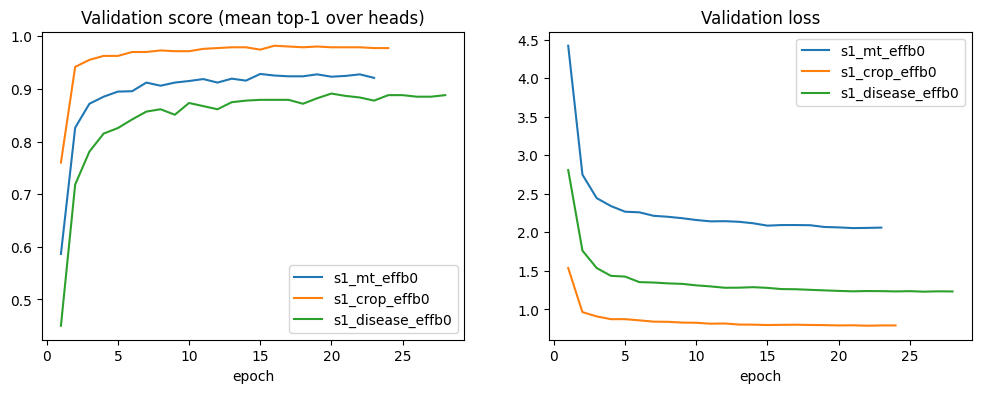

outputs/stage1a/eval/calibration_curve.png


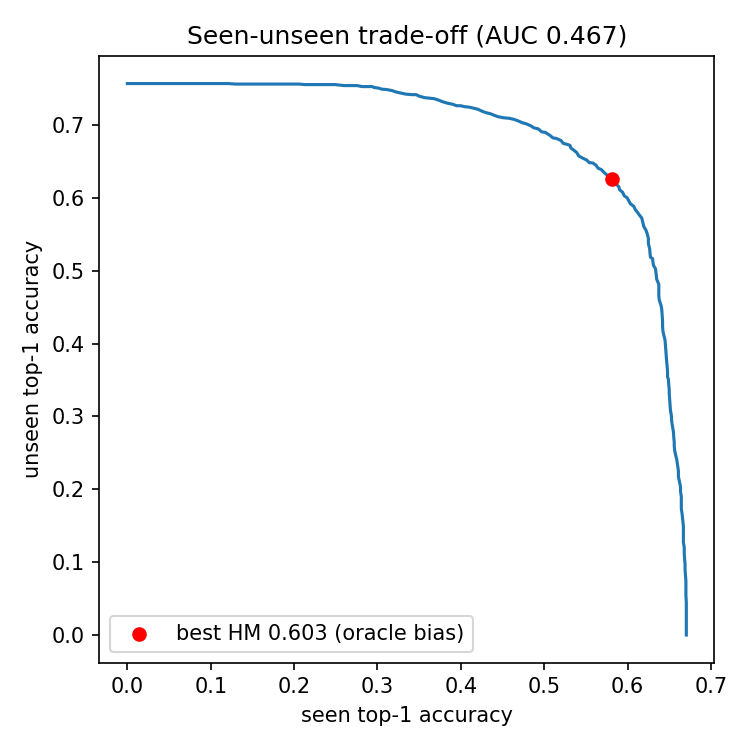

outputs/stage1a/eval/top_confusions_seen.png


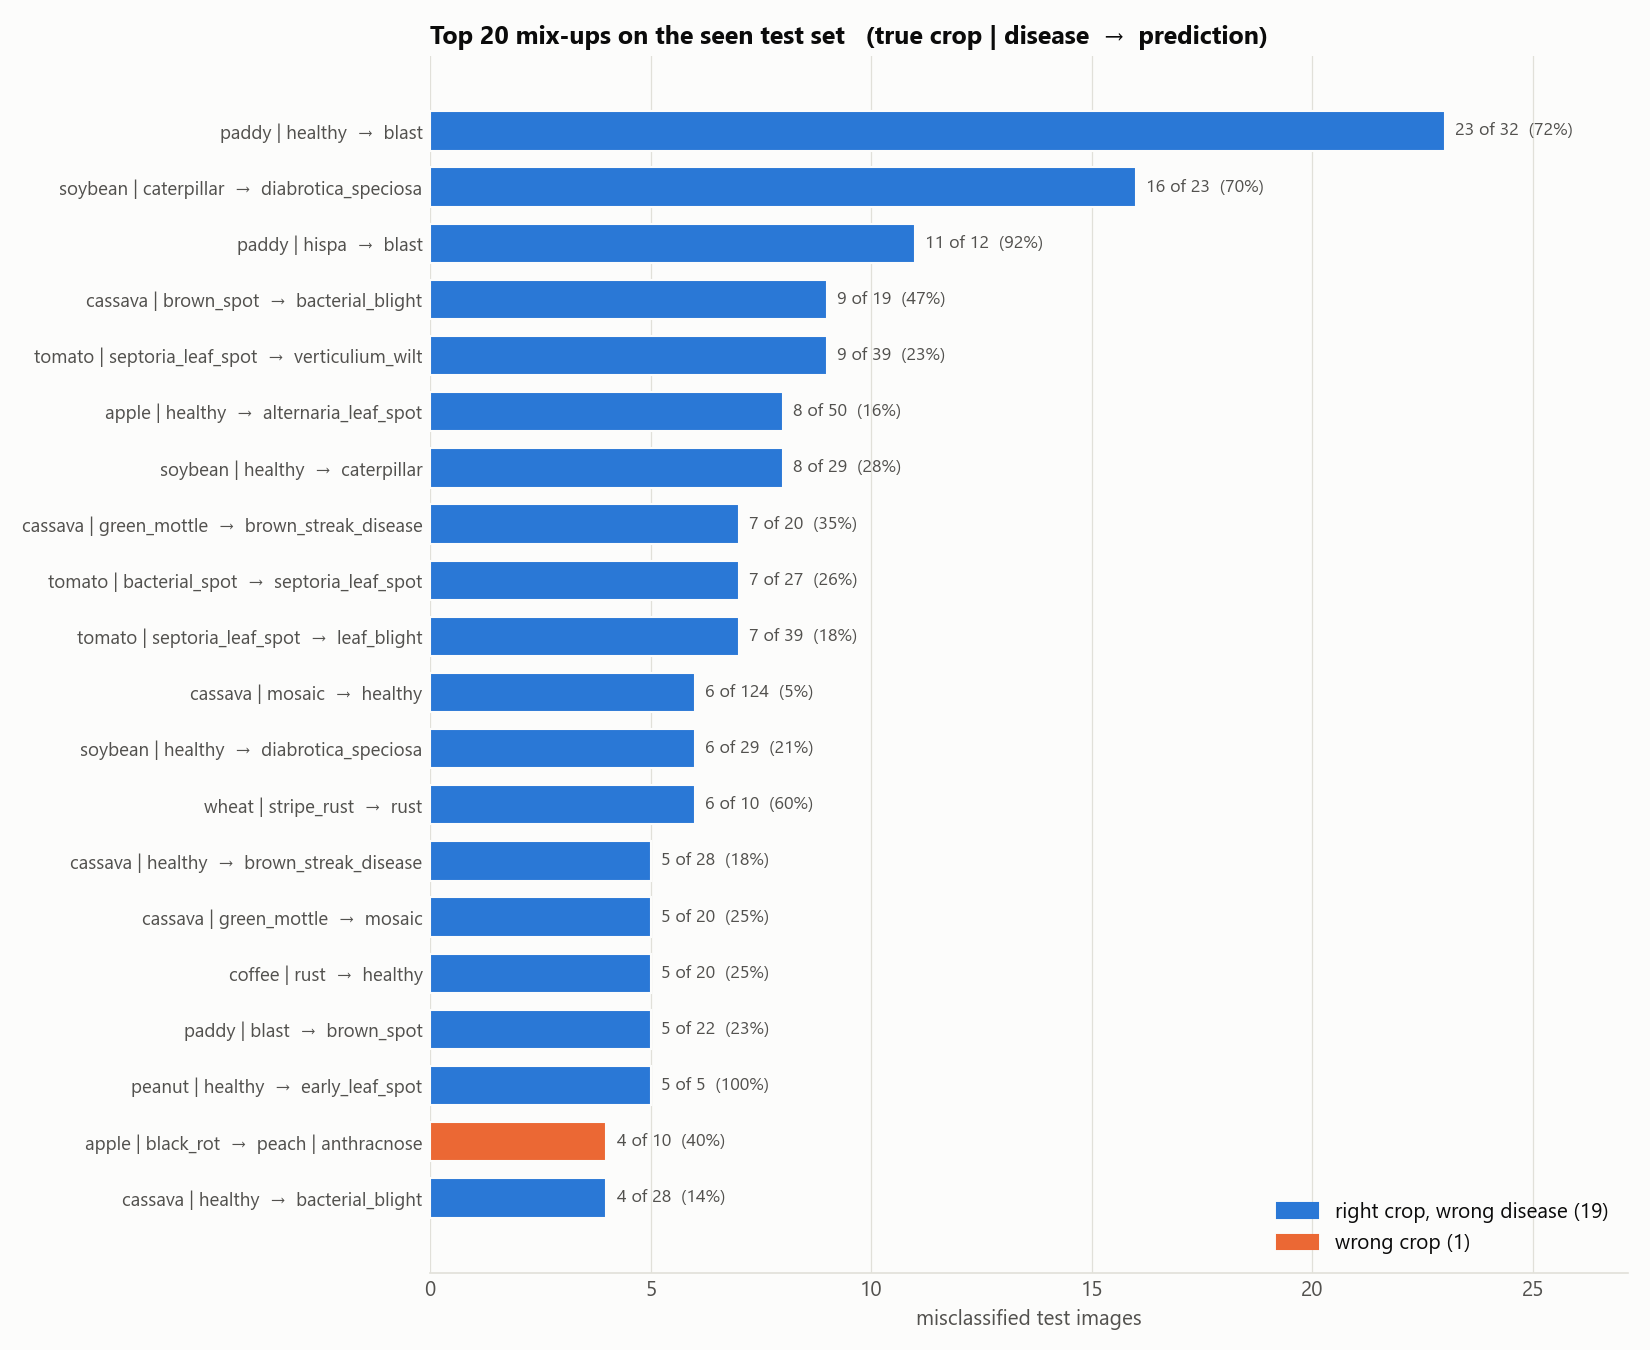

outputs/stage1b/eval/calibration_curve.png


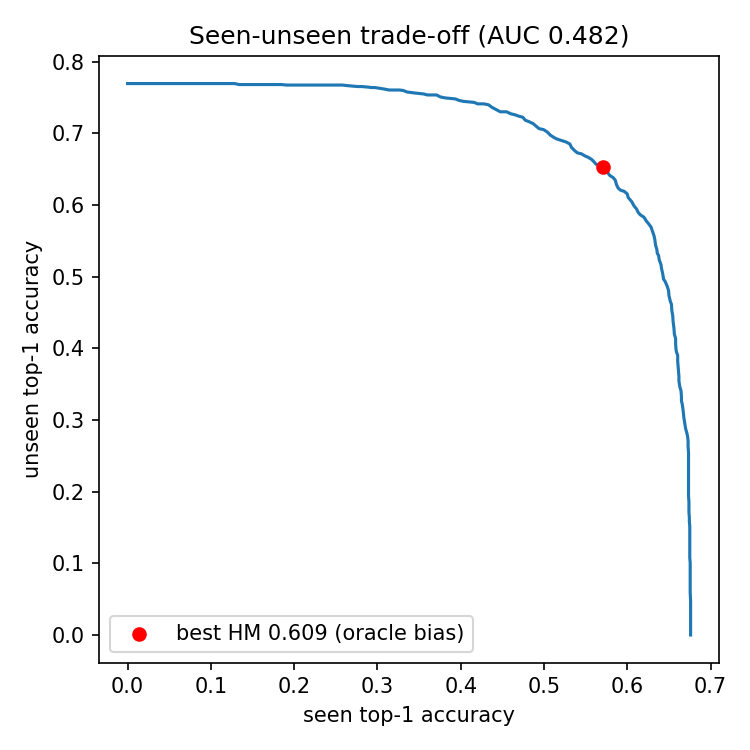

outputs/stage1b/eval/top_confusions_seen.png


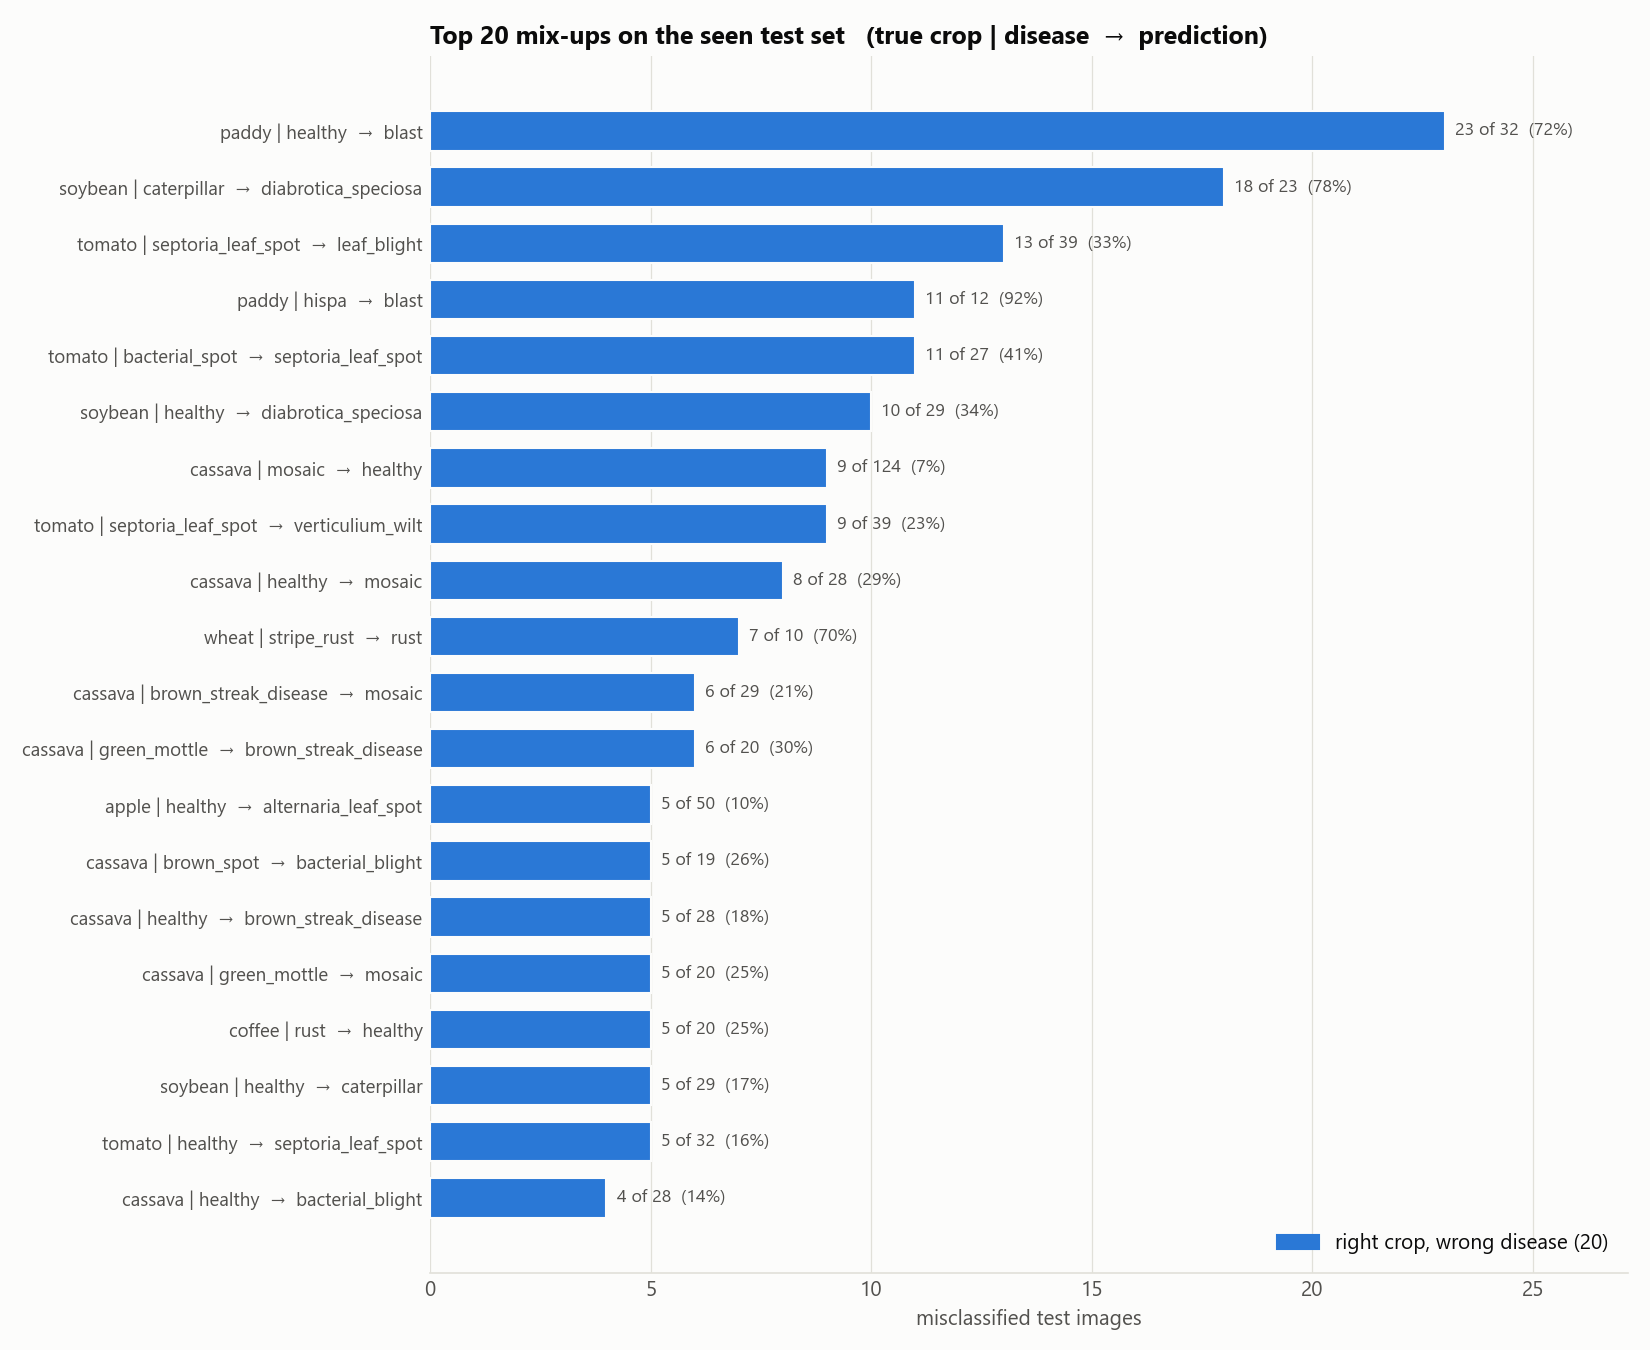

In [6]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Every metric training scheme §5 asks for, read from eval/metrics.json (never typed by hand).
rows = {}
for name in EVALS:
    path = f"outputs/{name}/eval/metrics.json"
    if not os.path.isfile(path):
        continue
    with open(path) as f:
        m = json.load(f)
    s, u = m["seen"], m["unseen"]
    rows[name] = {
        "seen crop top-1": s["crop"]["top1"],
        "seen disease top-1": s["disease"]["top1"],
        "seen pair top-1": s["composition"]["top1"],
        "seen pair top-5": s["composition"]["top5"],
        "unseen crop top-1": u["crop"]["top1"],
        "unseen disease top-1": u["disease"]["top1"],
        "unseen pair top-1": u["composition"]["top1"],
        "unseen pair top-5": u["composition"]["top5"],
        "unseen pair class-balanced": u.get("composition_class_balanced", {}).get("top1", float("nan")),
        "HM top-1": m["harmonic_mean"]["top1"],
        "HM top-5": m["harmonic_mean"]["top5"],
        "best HM (oracle bias sweep)": m["calibrated"]["best_hm"],
        "AUSUC": m["calibrated"]["auc"],
    }
if rows:
    print("Generalized setting (333 candidate pairs), best.pt. "
          "'best HM (oracle bias sweep)' picks the bias on the test sets: report it only next to AUSUC.")
    display(pd.DataFrame(rows).T.round(4))
else:
    print("No evaluation results yet.")

# Training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for exp in RUNS:
    hist = f"outputs/{exp}/history.csv"
    if os.path.isfile(hist):
        h = pd.read_csv(hist)
        ax[0].plot(h["epoch"], h["val_score"], label=exp)
        ax[1].plot(h["epoch"], h["val_loss"], label=exp)
ax[0].set(title="Validation score (mean top-1 over heads)", xlabel="epoch")
ax[1].set(title="Validation loss", xlabel="epoch")
for a in ax:
    a.legend()
plt.show()

for name in EVALS:
    for png in ["calibration_curve.png", "top_confusions_seen.png"]:
        path = f"outputs/{name}/eval/{png}"
        if os.path.isfile(path):
            print(path)
            display(Image(path, width=600))

## 7. Package the results for the team Drive

Collects the result folders with `best.pt` (the Colab notebook needs it to see the run as finished). `last.pt` is
left out to save space. With `SHARE_DIR` set, the folders are copied there. Otherwise it is zipped into
`outputs/share_s1_effb0_local.zip`: upload it, then unzip the folders into `AML_Group_Project/aml_runs`.

The small result files (no checkpoints) can also be committed to git as usual. `.gitignore` already keeps the
`.pt` files out.

In [7]:
import shutil
import zipfile

files = []
for folder in dict.fromkeys([*RUNS, *EVALS]):
    for root, _, fs in os.walk(f"outputs/{folder}"):
        files += [os.path.join(root, fn) for fn in fs if fn != "last.pt"]
assert files, "No results yet. Run the training cell first."

if SHARE_DIR:
    for p in files:
        dst = os.path.join(SHARE_DIR, os.path.relpath(p, "outputs"))
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copy2(p, dst)
    print(f"Copied {len(files)} files to {SHARE_DIR}")
else:
    zip_path = "outputs/share_s1_effb0_local.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in files:
            z.write(p, os.path.relpath(p, "outputs"))
    print(f"{len(files)} files -> {os.path.abspath(zip_path)} ({os.path.getsize(zip_path) / 2**20:.0f} MB)")
print("Now save this notebook (Ctrl+S) and upload it too.")

27 files -> c:\COS30082_ML_Project\outputs\share_s1_effb0_local.zip (50 MB)
Now save this notebook (Ctrl+S) and upload it too.
